**Programmer: python_scripts (Abhijith Warrier)**

**🔐 PYTHON SCRIPT TO DEMONSTRATE: *MODEL EXTRACTION***

Learn how repeated predictions from a controlled local classifier can help train a substitute that imitates its decisions.

**Scope:** synthetic two-dimensional data, local models, and labels only. No external API, real security detector, or private data is involved. The query interface simulates restricted access; a Python wrapper in this notebook is not a secure isolation boundary.

Run cells top to bottom. Requirements: `python -m pip install numpy scikit-learn matplotlib`.

---
## 🟢 1. Build the Local Target

Train a random forest on synthetic two-moon data. Its ordinary test accuracy measures agreement with known labels. Later, **fidelity** will measure agreement with the target's predictions—a different question.

In [1]:
import json
import platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

OUTPUT = Path(".")
X, y = make_moons(n_samples=1_500, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
target = RandomForestClassifier(
    n_estimators=100, max_depth=6, random_state=42, n_jobs=1
).fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_test, target.predict(X_test))
print(f"Target test accuracy: {baseline_accuracy:.2%}")

Target test accuracy: 97.07%


---
## 🔴 2. Collect Prediction Labels

The extraction routine knows the input schema and permitted region, but uses no target parameters, original training rows, or original labels. It submits new points and observes only class `0` or `1`.

Count **one query per input row**, even when rows are submitted together. Reuse a single nested pool so a 1,000-point experiment consumes 1,000 total extraction queries, not the sum of all plotted budgets.

In [2]:
LOW = np.array([-1.5, -1.0])
HIGH = np.array([2.5, 1.5])
BUDGETS = [25, 100, 250, 1_000]

class LocalPredictionAPI:
    """Toy local interface: validate inputs and count predicted rows."""
    def __init__(self, predict_function, limit):
        self._predict = predict_function
        self.limit = limit
        self.queries_used = 0

    def predict(self, points):
        points = np.asarray(points, dtype=float)
        if points.ndim != 2 or points.shape[1] != 2:
            raise ValueError("Expected an (n, 2) array")
        if not np.isfinite(points).all():
            raise ValueError("Inputs must be finite")
        if ((points < LOW) | (points > HIGH)).any():
            raise ValueError("Inputs outside the permitted region")
        if self.queries_used + len(points) > self.limit:
            raise RuntimeError("Query budget exceeded")
        labels = self._predict(points)
        self.queries_used += len(points)
        return labels

query_points = np.random.default_rng(7).uniform(LOW, HIGH, size=(max(BUDGETS), 2))
api = LocalPredictionAPI(target.predict, limit=max(BUDGETS))
query_labels = api.predict(query_points)
assert api.queries_used == 1_000
print(f"Extraction queries used: {api.queries_used}")

Extraction queries used: 1000


---
## 🔍 3. Train Substitutes and Measure Fidelity

Fit a fresh depth-six decision tree for each budget, using only queried inputs and returned labels. A separate evaluator compares each substitute with the target on 5,000 fresh uniform points from the same region.

**Fidelity = matching target predictions / evaluation points.** These evaluation labels never enter substitute training or model selection. The owner performs these additional predictions outside the extraction budget; the notebook does not claim all evaluation was obtained free through the restricted API.

In [3]:
evaluation_points = np.random.default_rng(99).uniform(LOW, HIGH, size=(5_000, 2))
# Owner-side evaluation: not exposed to the extraction routine.
reference_labels = target.predict(evaluation_points)
substitutes = {}
results = []
for budget in BUDGETS:
    substitute = DecisionTreeClassifier(max_depth=6, random_state=42)
    substitute.fit(query_points[:budget], query_labels[:budget])
    fidelity = accuracy_score(reference_labels, substitute.predict(evaluation_points))
    substitutes[budget] = substitute
    results.append({"queries": budget, "fidelity": float(fidelity)})
    print(f"{budget:>4} queries → {fidelity:.2%} agreement with target")

assert len(results) == len(BUDGETS)
assert all(0 <= row["fidelity"] <= 1 for row in results)

  25 queries → 91.00% agreement with target
 100 queries → 92.56% agreement with target
 250 queries → 97.10% agreement with target
1000 queries → 97.86% agreement with target


---
## 📈 4. Visualise the Learned Behaviour

Compare the target and the final substitute across the same region. Colours show predicted classes, not probabilities. The boundary separates their class regions. The target grid is computed by the owner for illustration, separately from extraction queries.

A visually similar boundary or high fidelity does not prove identical weights, architecture, training data, or behaviour outside this region. This is a single fixed-seed experiment; more queries do not guarantee improvement at every step.

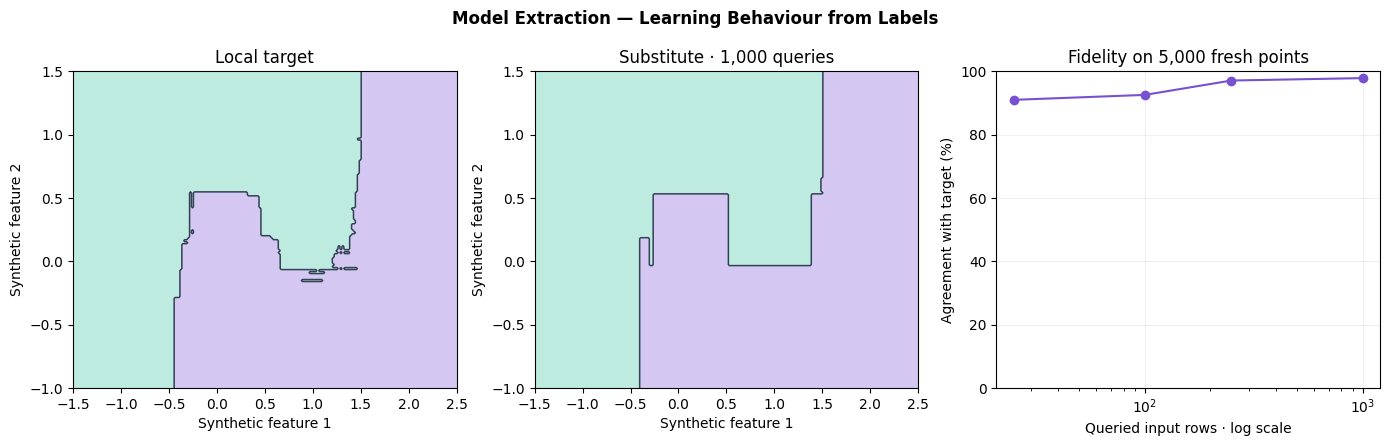

In [4]:
gx, gy = np.meshgrid(np.linspace(LOW[0], HIGH[0], 200),
                     np.linspace(LOW[1], HIGH[1], 160))
grid = np.column_stack([gx.ravel(), gy.ravel()])
target_map = target.predict(grid).reshape(gx.shape)
substitute_map = substitutes[max(BUDGETS)].predict(grid).reshape(gx.shape)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, labels, title in zip(axes[:2], [target_map, substitute_map],
                           ["Local target", "Substitute · 1,000 queries"]):
    ax.contourf(gx, gy, labels, levels=[-0.5, 0.5, 1.5], colors=["#BEEBDF", "#D4C8F2"])
    ax.contour(gx, gy, labels, levels=[0.5], colors="#334155", linewidths=1.1)
    ax.set(title=title, xlabel="Synthetic feature 1", ylabel="Synthetic feature 2")
axes[2].plot(BUDGETS, [r["fidelity"] * 100 for r in results], "o-", color="#7851D1")
axes[2].set(xscale="log", ylim=(0, 100), xlabel="Queried input rows · log scale",
            ylabel="Agreement with target (%)", title="Fidelity on 5,000 fresh points")
axes[2].grid(alpha=0.2)
fig.suptitle("Model Extraction — Learning Behaviour from Labels", fontweight="bold")
fig.tight_layout()
fig.savefig(OUTPUT / "model_extraction_results.png", dpi=180)
fig.savefig(OUTPUT / "model_extraction_results.pdf")
plt.show()

---
## 🛡️ 5. Verify a Query-Budget Control

A fresh interface enforces a total allowance of 250 rows for this simulated client. Train from those labels, then verify that one additional row is rejected without consuming budget.

This demonstrates enforcement, not complete extraction prevention. Labels obtained before the cap still reveal behaviour. Production controls need server-side identity, accounting, and monitoring; the local counter does not address multiple identities or coordinated querying.

In [5]:
limited_api = LocalPredictionAPI(target.predict, limit=250)
limited_labels = limited_api.predict(query_points[:250])
limited_substitute = DecisionTreeClassifier(max_depth=6, random_state=42).fit(
    query_points[:250], limited_labels
)
limited_fidelity = accuracy_score(reference_labels, limited_substitute.predict(evaluation_points))
blocked = False
try:
    limited_api.predict(query_points[250:251])
except RuntimeError as error:
    blocked = True
    print(error)
assert blocked and limited_api.queries_used == 250
assert np.array_equal(limited_labels, query_labels[:250])
assert np.isclose(limited_fidelity, results[2]["fidelity"])
print(f"Queries allowed: {limited_api.queries_used}; extra row blocked: {blocked}")
print(f"Fidelity already learned within the cap: {limited_fidelity:.2%}")

Query budget exceeded
Queries allowed: 250; extra row blocked: True
Fidelity already learned within the cap: 97.10%


---
## ✅ 6. Save the Evidence and Interpret It

The main run uses 1,000 extraction rows. The independent defence demonstration uses another 250. Owner-side test, evaluation, and plot predictions are separate and are not supplied to the substitute for training.

- Labels alone can reveal enough behaviour to train a useful approximation in a simple, known input domain.
- Fidelity is agreement with the target, not correctness against ground truth; a substitute can copy mistakes.
- Query caps constrain this interface but do not erase information already released.
- Authentication, per-client budgets, query-pattern monitoring, and limiting unnecessary output detail can reduce exposure. Their effectiveness requires testing; returning labels only is not a guarantee.
- This toy lab does not recover original parameters or training data, or establish what is possible against a larger model.

[Model extraction research: Tramèr et al.](https://arxiv.org/abs/1609.02943) · [Scikit-learn decision trees](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)

In [6]:
summary = {
    "environment": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                    "numpy": np.__version__, "recorded_at_utc": datetime.now(timezone.utc).isoformat()},
    "target_accuracy": float(baseline_accuracy), "results": results,
    "extraction_queries": api.queries_used, "evaluation_points": len(evaluation_points),
    "defence_queries": limited_api.queries_used, "extra_query_blocked": blocked,
    "limited_fidelity": float(limited_fidelity),
    "domain_low": LOW.tolist(), "domain_high": HIGH.tolist(),
}
(OUTPUT / "results.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
np.savez_compressed(OUTPUT / "visual_data.npz", gx=gx, gy=gy, target_map=target_map,
                    substitute_map=substitute_map, query_points=query_points, query_labels=query_labels,
                    **{f"map_{b}": substitutes[b].predict(grid).reshape(gx.shape) for b in BUDGETS})
print("Saved results, environment, and visualisation data.")

Saved results, environment, and visualisation data.
